# Notebook 1 — revisão 04 · conversão e adaptação geométrica parcial

A conversão e os resultados da revisão 03 são preservados nas células anteriores ao módulo novo. **Essas células anteriores não foram reexecutadas nesta revisão.**

Ao final, a seção **“Notebook 1 · revisão 04 — módulo IFC2SB parcial em Python”** acrescenta seis células de código executadas nesta revisão. Esse módulo também está disponível separadamente para execução direta, sem repetir a conversão Java.

O módulo examina a cozinha, recorta aberturas por face e registra coordenadas e estados da evidência no RDF. É uma adaptação parcial de código publicado, com extensão ambiente-face identificada e limites pendentes. Não certifica a completude da arquitetura.

# Notebook 1 — Conversão IFC–LBD, geometria e relações espaciais · revisão 03

**CIV2155 · Creche Pré-Escola Tipo 2 do FNDE · arquitetura ARQ-DTV R03.**

**Objetivo:** converter o IFC com o programa publicado IFCtoLBD, verificar a informação preservada, gravar a geometria XYZ no RDF e investigar a associação entre ambientes e paredes por testes geométricos rastreáveis.

**Requisitos:** ambientes → paredes geometricamente adjacentes → aberturas → preenchimentos declarados; geometria 3D, unidades, referencial e evidências no próprio grafo. A porta de uma parede compartilhada não é atribuída automaticamente a todos os cômodos que essa parede delimita.

O procedimento abrange os **41 ambientes**; a cozinha é um caso de consulta, não uma seleção manual de paredes. O IFC original é preservado por SHA-256. Não se realiza integração com a estrutura nem correção dos problemas do modelo.

**Natureza do resultado:** grafo experimental de informação declarada e relações geométricas qualificadas, acompanhado de limitações. Contato geométrico não comprova função, acessibilidade ou completude arquitetônica. Falhas e proximidades permanecem registradas.


## Fontes e contribuição aplicada

| Fonte | Contribuição | Forma de utilização |
|---|---|---|
| Bonduel et al. (2018), [artigo](https://ceur-ws.org/Vol-2159/04paper.pdf), [IFCtoLBD](https://github.com/jyrkioraskari/IFCtoLBD) | Conversão IFC–LBD | Execução do software dos autores, versão 2.49.0, mantendo a adaptação textual já documentada. |
| Huitzil et al. (2024), [DOI](https://doi.org/10.1016/j.jii.2024.100731), §§5, 6.3.3 | Preservação de informação e geometria | Comparação de produtos por GUID, cobertura geométrica, registro de parâmetros e versões. O benchmark dos autores, com IFCtoLBD 2.43.5, não é reproduzido. |
| Zhang, Beetz e De Vries (2018), [DOI](https://doi.org/10.3233/SW-180297), [GeometryConverter.java](https://github.com/BenzclyZhang/BimSPARQL/blob/dd7872ac7aab85e98e2d0177d80c878abb88a71e/src/main/java/nl/tue/ddss/bimsparql/geometry/convert/GeometryConverter.java) | Geometria em RDF | Adaptação do padrão `geom:hasGeometry` → `geom:asBody`, com malhas TIN Z completas. Não executa a classe Java BimSPARQL. |
| Lilis et al. (2025), [DOI](https://doi.org/10.1016/j.autcon.2025.106081), §§3.2–3.4, Fig.4 | Critérios de relação geométrica | Adaptação Python: normais opostas, distância máxima plano-ponto e interseção de projeções em um plano 3D. Não executa o GRC C++ dos autores. |
| Wang, Zhang e Yan (2024), [DOI](https://doi.org/10.1016/j.autcon.2024.105293); Jäkel et al. (2025), [DOI](https://doi.org/10.3390/buildings15050720) | Validação explícita | Shapes e controles específicos de BOT/GEOM/CIV elaborados para este ensaio. Não converte regras WHERE/EXPRESS nem copia os shapes ifcOWL dos autores. |
| Zhu et al. (2024), [BG-LoA](https://doi.org/10.5194/isprs-archives-XLVIII-4-2024-591-2024) | Delimitação do produto | Distingue converter instâncias, representar geometria e acrescentar relações; não se declara criada uma ontologia universal. |

O cálculo de interseção volumétrica utiliza a biblioteca aberta [Manifold](https://github.com/elalish/manifold), com `Mesh64`; difere da implementação BSP utilizada no artigo de Lilis. A adaptação geométrica foi confrontada com casos analíticos de contato, separação, rotação, concavidade, furo e sobreposição. Shapely opera somente sobre polígonos projetados no plano de cada face 3D, **não sobre a planta XY do edifício**.

**Não incorporado como solução pronta:** o método de Kiavarz et al. (2023), [DOI](https://doi.org/10.3390/buildings13020350), pressupõe `IfcSpace.BoundedBy`; o modelo não possui `IfcRelSpaceBoundary`. Os exemplos de Aydın (2026) dependem de SemanIFC, cujo pacote completo não foi confirmado, e não demonstram as relações espaciais exigidas. Os ensaios IFC2SB da revisão 02 permanecem históricos e não são apresentados como resultados bem-sucedidos desta revisão.

Documentação técnica: [IfcOpenShell: geometria](https://docs.ifcopenshell.org/ifcopenshell-python/geometry_processing.html), [RDFLib](https://rdflib.readthedocs.io/en/latest/), [BOT](https://w3c-lbd-cg.github.io/bot/), [SHACL](https://www.w3.org/TR/shacl/), [Manifold](https://manifoldcad.org/docs/html/).


## 1. Ambiente e arquivos de apoio

Os módulos contêm o código da adaptação, com as referências no cabeçalho. Cada arquivo é conferido por SHA-256. No Colab, são obtidos da pasta `consultas/notebook1_v03` do repositório; no computador, podem ficar em `codigo/`, junto deste notebook.


In [1]:
import os,sys,subprocess,json,hashlib,time,zipfile,shutil
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import version,PackageNotFoundError

VERSOES={"ifcopenshell":"0.8.4","numpy":"2.5.4","shapely":"2.2.0",
         "rdflib":"7.1.4","pyshacl":"0.30.1","manifold3d":"3.3.2"}
pendentes=[]
for nome,esperada in VERSOES.items():
    try:atual=version(nome)
    except PackageNotFoundError:atual=None
    if atual!=esperada:pendentes.append(nome+"=="+esperada)
if pendentes:subprocess.run([sys.executable,"-m","pip","install","-q"]+pendentes,check=True)
ROOT=Path(os.environ.get("CIV2155_N1", "/content/CIV2155_Notebook1_v03" if Path("/content").exists() else "CIV2155_Notebook1_v03")).resolve()
ROOT.mkdir(parents=True,exist_ok=True)
CODIGO=Path(os.environ.get("CIV2155_CODIGO_N1",Path.cwd()/"codigo")).resolve()
CODIGO.mkdir(parents=True,exist_ok=True)
def sha256(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
HASHES_MODULOS={'geometria_relacoes.py': 'ed014e7b6e68dad879587a71c0a2b2b2d36437d902e61389f0f71a48f9e42570', 'pipeline_arquitetura.py': 'f8b64c3baab9fa46d588db7eff4dbb39ca2fda0c8b4d4edda8c66c3ad13afb0f', 'validacao_e_consultas.py': '1a388194c9e3e5fdbd4b416967484c6d7974637b3c9ea78e86c128539e86f051', 'testar_geometria.py': '391687584208ceb3296903ac26400139c621647015c3c478e20b375fe6c5ce31'}
for nome,esperado in HASHES_MODULOS.items():
    destino=CODIGO/nome
    if not destino.exists():urlretrieve("https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/main/consultas/notebook1_v03/"+nome,destino)
    if sha256(destino)!=esperado:raise ValueError("Código diferente da versão registrada: "+nome)
sys.path.insert(0,str(CODIGO))
import ifcopenshell
from rdflib import Graph,RDF
from pipeline_arquitetura import *
from validacao_e_consultas import run_queries,validate_graph
from testar_geometria import run_tests
PASTA_RESULTADOS=ROOT/"resultados";PASTA_RESULTADOS.mkdir(exist_ok=True)
print("Versões:",{n:version(n) for n in VERSOES})
print("Pasta de execução:",ROOT)


Versões: {'ifcopenshell': '0.8.4', 'numpy': '2.5.4', 'shapely': '2.2.0', 'rdflib': '7.1.4', 'pyshacl': '0.30.1', 'manifold3d': '3.3.2'}
Pasta de execução: C:\Users\prcgu\OneDrive\Documentos\ChatGPT\Artigo da Disciplina BIM\desenvolvimento\revisao_notebook1_v03\execucao_notebook


## 2. Importação do IFC e inventário inicial

Seleciona todas as instâncias `IfcProduct` e inventaria as classes relevantes. A quantidade zero de limites declarados é uma ausência de informação, não uma prova de que não existem paredes delimitadoras. A origem é o IFC público preservado, sem alteração de suas entidades.


In [2]:
ARQUIVO_IFC=Path(os.environ.get("CIV2155_IFC_ORIGINAL",ROOT/"dados/TIPO2-ARQ-DTV_R03.ifc"))
if not ARQUIVO_IFC.exists():
    ARQUIVO_IFC.parent.mkdir(parents=True,exist_ok=True)
    z=ROOT/"arquitetura_original.zip"
    urlretrieve("https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/main/dados/fnde/arquitetura/TIPO2-ARQ-DTV_R03.ifc.zip",z)
    with zipfile.ZipFile(z) as pacote:ARQUIVO_IFC.write_bytes(pacote.read(ARQUIVO_IFC.name))
assert sha256(ARQUIVO_IFC)==EXPECTED_IFC
modelo=ifcopenshell.open(str(ARQUIVO_IFC))
inventario={c:len(modelo.by_type(c)) for c in ["IfcProduct","IfcSpace","IfcWall","IfcDoor","IfcWindow","IfcOpeningElement","IfcRelVoidsElement","IfcRelFillsElement","IfcRelSpaceBoundary"]}
save_json(PASTA_RESULTADOS/"inventario_origem.json",inventario)
print(json.dumps(inventario,ensure_ascii=False,indent=2))


{
  "IfcProduct": 2116,
  "IfcSpace": 41,
  "IfcWall": 457,
  "IfcDoor": 53,
  "IfcWindow": 39,
  "IfcOpeningElement": 184,
  "IfcRelVoidsElement": 184,
  "IfcRelFillsElement": 183,
  "IfcRelSpaceBoundary": 0
}


## 3. Preparação do IFCtoLBD e da correção textual preservada

Bonduel et al. (2018) fundamentam a utilização do conversor. A distribuição é 2.49.0 e as correções locais de Unicode/apóstrofos são as mesmas já documentadas na primeira versão. As duas classes Java são recompiladas e os dez testes de texto são repetidos. A leitura de caracteres é apoiada pela documentação [buildingSMART](https://technical.buildingsmart.org/resources/ifcimplementationguidance/string-encoding/) e [Java §3.3](https://docs.oracle.com/javase/specs/jls/se21/html/jls-3.html#jls-3.3).


In [3]:
MOTOR=Path(os.environ.get("CIV2155_MOTOR",ROOT/"motor"));MOTOR.mkdir(parents=True,exist_ok=True)
pacote_motor=MOTOR/"IFCtoLBD.zip"
if not pacote_motor.exists():urlretrieve("https://github.com/jyrkioraskari/IFCtoLBD/releases/download/2.49.0/IFCtoLBD.zip",pacote_motor)
HASH_MOTOR="49dc8833418cadf552fd688eca8f56499c5d1dad8783712aab56825b84bba14e"
assert sha256(pacote_motor)==HASH_MOTOR
lib=MOTOR/"IFCtoLBD/IFCtoLBD-Desktop_Java_21_lib"
if not lib.exists():
    with zipfile.ZipFile(pacote_motor) as z:z.extractall(MOTOR)
java=Path(os.environ.get("CIV2155_JAVA","/usr/lib/jvm/java-21-openjdk-amd64/bin/java"))
if not java.is_file():
    if os.name=="nt":raise RuntimeError("Definir CIV2155_JAVA com Java 21 JDK")
    subprocess.run(["apt-get","-qq","update"],check=True,stdout=subprocess.DEVNULL)
    subprocess.run(["apt-get","-qq","install","-y","openjdk-21-jdk-headless"],check=True,stdout=subprocess.DEVNULL)
classpath=str(lib/"*")
classe_cli="org.linkedbuildingdata.ifc2lbd.IFCtoLBDConverter_CLI"
pasta_resultados=PASTA_RESULTADOS
print(subprocess.run([str(java),"-version"],capture_output=True,text=True,check=True).stderr.splitlines()[0])


openjdk version "21.0.12.1" 2026-08-18 LTS


In [4]:
import difflib
import hashlib
import json
import os
import re
import subprocess
import time
from pathlib import Path
from urllib.request import urlretrieve
from rdflib import Graph

pasta_correcao = ROOT / "correcao_textual"
pasta_correcao.mkdir(exist_ok=True)
pasta_resultados_corrigidos = pasta_resultados / "correcao_textual"
pasta_resultados_corrigidos.mkdir(exist_ok=True)
commit_fonte = "ca7811b7132a843b85beee748d255f9b5b709e07"
base_fonte = "https://raw.githubusercontent.com/jyrkioraskari/IFCtoLBD/" + commit_fonte + "/"
fontes = {
    "StringOperations.java": (
        "IFCtoLBD/src/main/java/org/linkedbuildingdata/ifc2lbd/core/utils/StringOperations.java",
        "5f7e65b41d6ce9acd00e03c38070f533a6902575a3f201629cc3b56708dced13",
    ),
    "RDFWriter.java": (
        "IFCtoRDF/src/main/java/be/ugent/RDFWriter.java",
        "6924f236cb17fd6cf89bcf69e393a874a22f964be84d4c1e6a46c5cc01433621",
    ),
}
registro_fontes, diferencas = {}, []
for nome, (caminho, esperado) in fontes.items():
    original = pasta_correcao / ("original_" + nome)
    urlretrieve(base_fonte + caminho, original)
    dados = original.read_bytes()
    if hashlib.sha256(dados).hexdigest() != esperado:
        raise ValueError("Fonte diferente da versão documentada: " + nome)
    texto_original = dados.decode("utf-8")
    texto_corrigido = texto_original
    if nome == "StringOperations.java":
        padrao = r'(line = line\.replace\("\\\\X2\\\\([0-9A-Fa-f]{4})\\\\X0\\\\", ")[^"\n]*("\);)'
        texto_corrigido, quantidade = re.subn(
            padrao, lambda m: m[1] + "\\u" + m[2] + m[3], texto_original
        )
        if quantidade != 66:
            raise ValueError("A tabela Unicode tem uma estrutura não prevista.")
    else:
        inicio = "private static String filterExtras(String txt) {\n"
        acrescimo = (
            '\t\t// CIV2155: preserve the content of the parser string token.\n'
            '\t\tif (txt.startsWith("\'")) return txt.substring(1);\n'
        )
        if texto_original.count(inicio) != 1:
            raise ValueError("A função de leitura de texto não foi localizada.")
        texto_corrigido = texto_original.replace(inicio, inicio + acrescimo, 1)
    destino = pasta_correcao / nome
    destino.write_text(texto_corrigido, encoding="utf-8")
    registro_fontes[nome] = {
        "url": base_fonte + caminho, "sha256_original": esperado,
        "sha256_corrigido": hashlib.sha256(destino.read_bytes()).hexdigest(),
    }
    diferencas.extend(difflib.unified_diff(
        texto_original.splitlines(keepends=True),
        texto_corrigido.splitlines(keepends=True),
        fromfile="original/" + nome, tofile="corrigido/" + nome,
    ))
(pasta_resultados_corrigidos / "alteracoes.patch").write_text("".join(diferencas), encoding="utf-8")

# O compilador é necessário somente para preparar as duas classes modificadas.
javac = Path(str(java)).with_name("javac.exe" if os.name=="nt" else "javac")
if not javac.is_file():
    subprocess.run(["apt-get", "-qq", "update"], check=True, stdout=subprocess.DEVNULL)
    subprocess.run(["apt-get", "-qq", "install", "-y", "openjdk-21-jdk-headless"],
                   check=True, stdout=subprocess.DEVNULL)
classes_corrigidas = pasta_correcao / "classes"
classes_corrigidas.mkdir(exist_ok=True)
subprocess.run([
    str(javac), "-encoding", "UTF-8", "-cp", classpath, "-d", str(classes_corrigidas),
    str(pasta_correcao / "StringOperations.java"), str(pasta_correcao / "RDFWriter.java"),
], check=True, capture_output=True, text=True)
classpath_corrigido = str(classes_corrigidas) + os.pathsep + classpath
javap = Path(str(java)).with_name("javap.exe" if os.name=="nt" else "javap")
for classe in ["be.ugent.RDFWriter", "org.linkedbuildingdata.ifc2lbd.core.utils.StringOperations"]:
    assinaturas = [
        subprocess.run([str(javap), "-public", "-cp", cp, classe],
                       check=True, capture_output=True, text=True).stdout
        for cp in [classpath, classpath_corrigido]
    ]
    if assinaturas[0] != assinaturas[1]:
        raise ValueError("A classe corrigida tem interface incompatível: " + classe)

# Testes independentes: caracteres isolados, sequências combinadas e apóstrofos.
codigo_teste = r'''
import org.linkedbuildingdata.ifc2lbd.core.utils.StringOperations;
public class TesteTextosCIV2155 {
 public static void main(String[] args) throws Exception {
  String[][] unicode = {
   {"BER\\X2\\00C7\\X0\\ARIO", "BER\u00C7ARIO"},
   {"SOL\\X2\\00C1\\X0\\RIO", "SOL\u00C1RIO"},
   {"Servi\\X2\\00E7\\X0\\o", "Servi\u00E7o"},
   {"CIRCULA\\X2\\00C700C3\\X0\\O", "CIRCULA\u00C7\u00C3O"},
   {"COZINHA", "COZINHA"},
   {"CASTELO D'\\X2\\00C1\\X0\\GUA", "CASTELO D'\u00C1GUA"}
  };
  for (String[] par : unicode)
   if (!StringOperations.handleUnicode(par[0]).equals(par[1]))
    throw new AssertionError("Unicode: " + par[0]);
  java.lang.reflect.Method filtro =
   Class.forName("be.ugent.RDFWriter").getDeclaredMethod("filterExtras", String.class);
  filtro.setAccessible(true);
  String[][] tokens = {
   {"'CASTELO D'\u00C1GUA", "CASTELO D'\u00C1GUA"},
   {"'COZINHA", "COZINHA"}, {"'A=B", "A=B"}, {"'d'agua", "d'agua"}
  };
  for (String[] par : tokens)
   if (!filtro.invoke(null, par[0]).equals(par[1]))
    throw new AssertionError("Token: " + par[0]);
  System.out.println("10/10 testes de texto aprovados.");
 }
}
'''
teste_java = pasta_correcao / "TesteTextosCIV2155.java"
teste_java.write_text(codigo_teste, encoding="utf-8")
subprocess.run([str(javac), "-encoding", "UTF-8", "-cp", classpath_corrigido,
                "-d", str(classes_corrigidas), str(teste_java)], check=True, capture_output=True)
teste = subprocess.run([str(java), "-cp", classpath_corrigido, "TesteTextosCIV2155"],
                       check=True, capture_output=True, text=True)
(pasta_resultados_corrigidos / "testes_textos.txt").write_text(teste.stdout, encoding="utf-8")
print(teste.stdout.strip())


save_json(pasta_resultados_corrigidos/"fontes_e_testes.json",{"fontes":registro_fontes,"testes":teste.stdout.strip()})


10/10 testes de texto aprovados.


## 4. Conversão semântica com inclusão explícita dos elementos

A conversão inicial de 411 triplas era um recorte de ambientes. Nesta revisão, `--hasIfc_based_elements=true` habilita os elementos no [código central dos autores](https://github.com/jyrkioraskari/IFCtoLBD/blob/ca7811b7132a843b85beee748d255f9b5b709e07/IFCtoLBD/src/main/java/org/linkedbuildingdata/ifc2lbd/core/IFCtoLBDConverterCore.java). Mantém-se PROPS L1.

A opção de geometria do conversor fica desativada **porque a geometria completa é materializada na etapa seguinte, com o IfcOpenShell**. Isso evita confundir as caixas envolventes avaliadas em Huitzil et al. (§6.3.3) com os sólidos necessários ao teste espacial. As representações têm origem no mesmo IFC e são ligadas pelo GUID.


In [5]:
RDF_CONVERTIDO=PASTA_RESULTADOS/"arquitetura_ifctolbd.ttl"
cmd=[str(java),"-Xmx4g","-Dfile.encoding=UTF-8","-cp",classpath_corrigido,classe_cli,str(ARQUIVO_IFC),
 "--url="+BASE,"--target_file="+str(RDF_CONVERTIDO),"--level=1","--hasBuildingElements=true",
 "--hasBuildingElementProperties=true","--hasIfc_based_elements=true","--hasSeparateBuildingElementsModel=false",
 "--hasSeparatePropertiesModel=false","--propertiesAsPropertySets=false","--hasUnits=true","--hasGeometry=false","--ifcOWL=false"]
inicio=time.perf_counter()
registro_path=PASTA_RESULTADOS/"registro_conversao.json"
registro_anterior=json.loads(registro_path.read_text(encoding="utf8")) if registro_path.exists() else {}
conversao_reutilizada=bool(RDF_CONVERTIDO.exists() and registro_anterior.get("sha256_ifc")==EXPECTED_IFC
    and registro_anterior.get("sha256_motor")==HASH_MOTOR and registro_anterior.get("comando")==cmd
    and registro_anterior.get("sha256_rdf")==sha256(RDF_CONVERTIDO))
if not conversao_reutilizada:
    with (PASTA_RESULTADOS/"conversao.log").open("w",encoding="utf8") as log:
        processo=subprocess.run(cmd,cwd=PASTA_RESULTADOS,stdout=log,stderr=subprocess.STDOUT,timeout=1800)
    processo.check_returncode()
assert sha256(ARQUIVO_IFC)==EXPECTED_IFC
grafo_convertido=Graph().parse(RDF_CONVERTIDO,format="turtle")
registro_conversao={"motor":"IFCtoLBD 2.49.0 com correção textual documentada","sha256_motor":HASH_MOTOR,
 "sha256_ifc":EXPECTED_IFC,"sha256_rdf":sha256(RDF_CONVERTIDO),"comando":cmd,"retorno":0,
 "triplas":len(grafo_convertido),"cache_reutilizado":conversao_reutilizada,
 "segundos_execucao_original":registro_anterior.get("segundos_execucao_original",registro_anterior.get("segundos")) if conversao_reutilizada else time.perf_counter()-inicio,
 "segundos":time.perf_counter()-inicio}
save_json(PASTA_RESULTADOS/"registro_conversao.json",registro_conversao)
print("Conversão:",len(grafo_convertido),"triplas;",round(registro_conversao["segundos"],1),"s")


Conversão: 56961 triplas; 7.8 s


## 5. Geometria dos produtos: coordenadas, unidades e qualidade

Extrai malhas trianguladas XYZ no referencial cartesiano do projeto, em metros, com subtrações de aberturas preservadas. Não substitui sólidos por caixas. Toda falha é inventariada por GUID; não se fabrica geometria para uma entidade cujo processamento falhou.

O cache só pode ser reutilizado se a fonte, os parâmetros, a versão e os arquivos de malha conferirem. Sua reutilização é registrada. A execução sem cache pode levar vários minutos. Isso é separado do tempo de conversão IFCtoLBD.

**Precisão e triangulação:** o RDF conserva as malhas trianguladas produzidas pelo IfcOpenShell, não a representação paramétrica integral do IFC. Nesta execução, `mesher-linear-deflection=0.001 m`, `mesher-angular-deflection=0.5 rad` e `precision=0.00001 m` foram registrados no inventário. O limiar estrito de 0,01 mm é um critério experimental sobre essas malhas; não demonstra exatidão física nessa escala, em especial nas superfícies curvas. A influência conjunta da triangulação e dos limiares requer avaliação de sensibilidade. Resultado sem adjacência qualificada não significa ambiente sem paredes.


In [6]:
CACHE=ROOT/"malhas"
cache_preexistente=(CACHE/"inventario_geometria.json").exists()
inicio=time.perf_counter()
geometria=extract_geometry(ARQUIVO_IFC,CACHE)
registro_geometria={"cache_reutilizado":cache_preexistente,"segundos_nesta_chamada":time.perf_counter()-inicio,
 "segundos_extracao_registrada":geometria["segundos"],"produtos_com_representacao":len(geometria["entidades"]),
 "malhas_disponiveis":sum("cache" in r for r in geometria["entidades"]),
 "falhas":[r for r in geometria["entidades"] if "erro" in r]}
save_json(PASTA_RESULTADOS/"registro_geometria.json",registro_geometria)
print(json.dumps(registro_geometria,ensure_ascii=False,indent=2))


{
  "cache_reutilizado": true,
  "segundos_nesta_chamada": 8.243361399989226,
  "segundos_extracao_registrada": 372.88869110000087,
  "produtos_com_representacao": 2112,
  "malhas_disponiveis": 2109,
  "falhas": [
    {
      "guid": "3Ak27VgDnEHPbsNyce8LHn",
      "classe": "IfcWall",
      "id": 121015,
      "nome": "Parede-110",
      "long_name": null,
      "erro": "Malha sem vértices XYZ ou índices triangulares"
    },
    {
      "guid": "292djSli13QOK5kurtYpT5",
      "classe": "IfcWall",
      "id": 132289,
      "nome": "Parede-110",
      "long_name": null,
      "erro": "Malha sem vértices XYZ ou índices triangulares"
    },
    {
      "guid": "3jsNVkT0TC4eoeR3CC7hwe",
      "classe": "IfcWall",
      "id": 132294,
      "nome": "Parede-110",
      "long_name": null,
      "erro": "Malha sem vértices XYZ ou índices triangulares"
    }
  ]
}


## 6. Testes independentes da implementação geométrica

Antes do modelo real, são testados casos com resposta analítica conhecida. A caixa é só um filtro: o caso côncavo mostra que caixas sobrepostas não estabelecem contato. A rotação 3D e o furo verificam que a rotina não depende de uma planta retangular preenchida. Esses testes avaliam o código, não substituem a validação arquitetônica do modelo.


In [7]:
testes=run_tests()
save_json(PASTA_RESULTADOS/"testes_geometria.json",testes)
print(len(testes),"testes geométricos aprovados")
for t in testes:print("OK —",t["teste"])


12 testes geométricos aprovados
OK — Face comum: área analítica 1 m² e volume comum zero
OK — Vão de 1 mm: proximidade, sem adjacência materializada
OK — Vão de 10 mm: nenhuma relação no limiar de 2 mm
OK — Contato só em aresta: não constitui interface com área
OK — Contato só em ponto: sem falsa adjacência por face
OK — Rotação e translação 3D: contato preservado fora da planta XY
OK — Sólido em L: sobreposição de caixas sem contato real
OK — Interface com furo: área 0,75 m², sem preencher o vazio
OK — Sobreposição volumétrica: não declarar adjacência disjunta
OK — Malha aberta: recusa da validação volumétrica
OK — Orientação global invertida: normalização só na malha derivada
OK — Coordenada inválida: rejeição explícita


## 7. Relações entre todos os ambientes e as paredes

Aplica os três critérios de adjacência da Figura 4 de Lilis et al. (2025). Uma verificação adicional de interseção volumétrica evita promover contato com sobreposição a uma adjacência de sólidos disjuntos. As duas bibliotecas geométricas têm papéis diferentes: Shapely calcula a interseção de projeções de faces; Manifold verifica interseção de sólidos triangulados.

Parâmetros deste ensaio, definidos antes da execução: distância estrita **0,01 mm**; proximidade **2 mm**; desvio angular **0,1°**; área mínima **1 mm²**; volume de interseção admitido por tolerância numérica **10⁻⁸ m³**. Não são valores atribuídos ao artigo e não são ajustados para aumentar a quantidade de relações.

As situações permanecem distintas: adjacência geométrica no limiar numérico; proximidade; contato com interseção volumétrica; contato sem sólido validado. Uma parede pode estar associada a mais de um ambiente.

Falhas de projeção ou interseção são registradas por par e no grafo de avaliação, sem corrigir polígonos automaticamente e sem inferir ausência ou presença de vínculo arquitetônico. A execução pode reutilizar conversão e malhas conferidas por hash/configuração, identificando o cache no registro; as relações e validações são recalculadas.


In [8]:
relacoes=contacts_all_spaces(modelo,CACHE,geometria,PASTA_RESULTADOS/"relacoes")
from collections import Counter
print("Situações:",dict(Counter(r["status"] for r in relacoes["pares"])))
print("Ambientes processados:",len(relacoes["cobertura"]))
print("Pares com falha geométrica preservada:",len(relacoes["falhas_processamento"]))


06 INFANTIL 1 : 0 paredes adjacentes no critério geométrico


06 INFANTIL 2/3 : 12 paredes adjacentes no critério geométrico


06 INFANTIL 4 : 0 paredes adjacentes no critério geométrico


06 INFANTIL 5 : 0 paredes adjacentes no critério geométrico


11 SANIT. INFANTIL FEM. : 18 paredes adjacentes no critério geométrico


...

03

 LIXO : 3 paredes adjacentes no critério geométrico


10 FRALDÁRIO : 0 paredes adjacentes no critério geométrico


32 CIRCULAÇÃO : 1 paredes adjacentes no critério geométrico


Situações: {'contato_sem_validacao_volumetrica': 194, 'adjacencia_geometrica_no_limiar_numerico': 135, 'contato_com_intersecao_volumetrica': 84, 'proximidade_de_superficies': 18}
Ambientes processados: 41
Pares com falha geométrica preservada: 17


## 8. Construção do RDF enriquecido e comparação de preservação

Grava as malhas completas como `TIN Z`, segundo o padrão GEOM/BimSPARQL. Os dados são separados em grafos nomeados: conversão, relações declaradas no IFC, geometria, relações geométricas derivadas, candidatos e avaliação. A união também é salva em Turtle para consulta.

Cada relação derivada conserva GUIDs, fonte, referência metodológica, limiares, área, volume e a superfície de contato calculada. `IfcRelVoidsElement` e `IfcRelFillsElement` fornecem parede → abertura → preenchimento. Uma cadeia assim formada não significa automaticamente que o preenchimento atende ao cômodo.

A comparação por classe e GUID torna explícitas as entidades preservadas pelo conversor e as que receberam geometria. Três dimensões numéricas de uma caixa não substituem a malha. A vinculação ao referencial do projeto não demonstra alinhamento com outro IFC.


In [9]:
PASTA_RDF=PASTA_RESULTADOS/"rdf"
grafo_final,registro_rdf=build_dataset(modelo,RDF_CONVERTIDO,CACHE,geometria,relacoes,PASTA_RDF)
print(json.dumps(registro_rdf,ensure_ascii=False,indent=2))


{
  "triplas_por_grafo": {
    "conversao": 56961,
    "declarado": 18081,
    "geometria": 35853,
    "derivado": 3742,
    "candidatos": 9162,
    "avaliacao": 130
  },
  "triplas_uniao": 117591,
  "produtos_com_geometria": 2109,
  "classes": [
    {
      "classe": "IfcSpace",
      "origem": 41,
      "na_conversao": 41,
      "com_geometria_RDF": 41
    },
    {
      "classe": "IfcWall",
      "origem": 457,
      "na_conversao": 457,
      "com_geometria_RDF": 454
    },
    {
      "classe": "IfcDoor",
      "origem": 53,
      "na_conversao": 53,
      "com_geometria_RDF": 53
    },
    {
      "classe": "IfcWindow",
      "origem": 39,
      "na_conversao": 39,
      "com_geometria_RDF": 39
    },
    {
      "classe": "IfcOpeningElement",
      "origem": 184,
      "na_conversao": 184,
      "com_geometria_RDF": 184
    },
    {
      "classe": "IfcCovering",
      "origem": 631,
      "na_conversao": 631,
      "com_geometria_RDF": 631
    },
    {
      "classe": "IfcRoof"

## 9. Consultas ao RDF efetivamente salvo

Reabre o Turtle e exporta as consultas `.rq` e as respostas `.csv`. A consulta da cozinha percorre as relações gravadas no RDF; não usa lista manual de paredes. Há consultas de geometrias, evidências, casos não qualificados, paredes compartilhadas e ambientes sem adjacência demonstrada. O arquivo completo pode ser grande por preservar a geometria dos produtos.


In [10]:
respostas=run_queries(PASTA_RDF/"arquitetura_enriquecida.ttl",PASTA_RESULTADOS/"consultas")
print(json.dumps(respostas,ensure_ascii=False,indent=2))
print("Aviso: a consulta parede–abertura–preenchimento não atribui automaticamente a porta ao cômodo.")


{
  "01_Geometria_dos_Ambientes": 41,
  "02_Cozinha_Paredes_Aberturas_Preenchimentos": 14,
  "03_Justificativa_das_Adjacencias": 135,
  "04_Proximidades_e_Contatos_Nao_Qualificados": 296,
  "05_Paredes_Compartilhadas": 33,
  "06_Ambientes_sem_Adjacencia_Qualificada": 12
}
Aviso: a consulta parede–abertura–preenchimento não atribui automaticamente a porta ao cômodo.


## 10. Validação e controle negativo

Verifica identidade dos ambientes, geometria, unidade, referencial e proveniência das evidências. O controle negativo remove a ligação geométrica de um ambiente em uma cópia na memória; o validador deve detectar a violação. O RDF salvo não é alterado.

As regras são específicas deste produto, apoiadas na estratégia de SHACL dos artigos, e não constituem validação integral do esquema IFC ou certificação de completude. Casos que não atendem aos critérios geométricos continuam no grafo de candidatos.


In [11]:
validacao=validate_graph(PASTA_RDF/"arquitetura_enriquecida.ttl",PASTA_RESULTADOS/"validacao")
print(json.dumps(validacao,ensure_ascii=False,indent=2))
assert validacao["conforme_regras_declaradas"],"Consultar relatório SHACL: regras declaradas não atendidas"
assert sha256(ARQUIVO_IFC)==EXPECTED_IFC


{
  "conforme_regras_declaradas": true,
  "violacoes": 0,
  "limite": "Não demonstra completude arquitetônica nem valida todas as restrições IFC/EXPRESS.",
  "adjacencias_derivadas_com_evidencia": 135,
  "adjacencias_totais_incluindo_conversor": 135,
  "controle_negativo_ambiente_sem_geometria_detectado": true
}


## 11. Produto, limitações e exportação

O resultado é um grafo consultável com dados e relações rastreáveis, geometria explícita e diagnóstico por ambiente. Não é uma demonstração de que toda a ontologia arquitetônica está completa. Não se realizam correções no IFC nem soluções para integração com a estrutura. Relações ausentes, falhas de geometria, interseções e dependência dos limiares constituem resultados para discussão no artigo.

Os arquivos de saída, código, versões, hashes, consultas, testes e referências acompanham o notebook. A execução abaixo compacta os resultados para permitir armazenamento e abertura posterior; não envia mensagens nem publica arquivos automaticamente.


In [12]:
resumo={"sha256_ifc_preservado":sha256(ARQUIVO_IFC),"versoes":{n:version(n) for n in VERSOES},
 "triplas_conversao":len(grafo_convertido),"triplas_enriquecidas":registro_rdf["triplas_uniao"],
 "ambientes_processados":len(relacoes["cobertura"]),"malhas_RDF":registro_rdf["produtos_com_geometria"],
 "falhas_geometricas":len(registro_geometria["falhas"]),"testes_geometricos_aprovados":len(testes),
 "falhas_processamento_relacoes":len(relacoes["falhas_processamento"]),
 "validacao":validacao,"cozinha":[r for r in relacoes["cobertura"] if r["ambiente"]=="COZINHA"],
 "limites":["Não demonstra completude arquitetônica.","Não associa uma porta ao cômodo por transitividade via parede.",
 "Não gera limites IFC de segundo nível.","Não reconcilia arquitetura com estrutura.","Amostra única FNDE; requer avaliação arquitetônica e de sensibilidade."],
 "saidas":{p.relative_to(PASTA_RESULTADOS).as_posix():sha256(p) for p in PASTA_RESULTADOS.rglob("*") if p.is_file()}}
save_json(PASTA_RESULTADOS/"manifesto_execucao_v03.json",resumo)
PACOTE=Path(shutil.make_archive(str(ROOT/"CIV2155_Notebook1_v03_Resultados"),"zip",PASTA_RESULTADOS))
print(json.dumps({k:v for k,v in resumo.items() if k!="saidas"},ensure_ascii=False,indent=2))
print("Pacote de resultados:",PACOTE.name,"—",PACOTE.stat().st_size,"bytes")


{
  "sha256_ifc_preservado": "0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a",
  "versoes": {
    "ifcopenshell": "0.8.4",
    "numpy": "2.5.4",
    "shapely": "2.2.0",
    "rdflib": "7.1.4",
    "pyshacl": "0.30.1",
    "manifold3d": "3.3.2"
  },
  "triplas_conversao": 56961,
  "triplas_enriquecidas": 117591,
  "ambientes_processados": 41,
  "malhas_RDF": 2109,
  "falhas_geometricas": 3,
  "testes_geometricos_aprovados": 12,
  "falhas_processamento_relacoes": 17,
  "validacao": {
    "conforme_regras_declaradas": true,
    "violacoes": 0,
    "limite": "Não demonstra completude arquitetônica nem valida todas as restrições IFC/EXPRESS.",
    "adjacencias_derivadas_com_evidencia": 135,
    "adjacencias_totais_incluindo_conversor": 135,
    "controle_negativo_ambiente_sem_geometria_detectado": true
  },
  "cozinha": [
    {
      "GlobalId": "3UFjAT4k55zg_Pqo6VMw5l",
      "ambiente": "COZINHA",
      "malha_disponivel": true,
      "pares_preselecionados_bbox": 34,
   

# Notebook 1 · revisão 04 — módulo IFC2SB parcial em Python

Complemento executável à conversão IFC–LBD da revisão 03. **Objetivo:** testar rotinas geométricas publicadas em um piloto da cozinha, preservar coordenadas no RDF e distinguir candidatos, separações e interpenetrações.

Fonte científica: [Fichter et al. (2021)](https://doi.org/10.26868/25222708.2021.30156). [Código dos autores, commit fixado](https://github.com/RWTH-E3D/IFC2SB/tree/96a89cdff65f13279c0c3ce67e729ad9f9f5adad). [Mapa das funções, diferenças e licença](https://github.com/prcgui/bim-ontology-CIV2155/tree/main/consultas/ifc2sb_python_v01).

Trata-se de portabilidade parcial com uma extensão ambiente-face explicitada, não de reconstrução completa ou arquitetura validada. O IFC original permanece intacto.

## 1. Preparar as fontes

O módulo pode ser executado nesta pasta ou no Colab. Arquivos baixados são confrontados com hashes fixados nesta versão do notebook. Para um ambiente novo, são instaladas as versões indicadas; ambientes com versões diferentes devem ser reiniciados e preparados conforme `requirements.txt`.

In [1]:
# Preparação técnica: bibliotecas fixadas e fontes verificadas por SHA-256.
# Referências científicas e diferenças: README.md do módulo (célula anterior).
from pathlib import Path
import sys,subprocess,importlib.util,urllib.request,hashlib,json
local=Path.cwd()
if (local/'ifc2sb_faces.py').exists():
    modulo=local
else:
    modulo=local/'ifc2sb_python_v01';modulo.mkdir(exist_ok=True)
EXPECTED={'ifc2sb_faces.py': '078cbc2c93c6f81854eb26738ddf26d31d34d3196c7533b8e54e734113d6a155', 'piloto.py': '71cd473ccc9bfdda5f8d89982046ca37e5991341e5412d7e4cb1c6e3b6fb828a', 'exportar_rdf.py': 'dc2e81194d029445f2697c2f6ab2b04458355915021176a49dbf7af218ebfda1', 'testar_adaptacao.py': 'ad4a1024b82130cfc5399b1dc3dd7ebf4b12cda1b1d82f53233db3097f7c984a', 'referencia_cpp/Resultado_CPP.json': '2e7cfc73670a63e77db9ce4cf0560dea2c51e5d2cc93ad1762be68bd08f83332', 'README.md': '5b70d51f757b14a28c0e9f96152d684b10c3056f6d56ad3ed73f724045ac7171', 'LICENSE': '3972dc9744f6499f0f9b2dbf76696f2ae7ad8af9b23dde66d6af86c9dfb36986', 'Manifesto_Fontes.json': 'dd994dce951b0d70b2deab489f80b8042fce0864aa3ffc55bc9e93cc29a7c292'}
url='https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/main/consultas/ifc2sb_python_v01/'
for name,digest in EXPECTED.items():
    target=modulo/name;target.parent.mkdir(parents=True,exist_ok=True)
    if not target.exists():urllib.request.urlretrieve(url+name,target)
    assert hashlib.sha256(target.read_bytes()).hexdigest()==digest, f'Fonte divergente: {name}'
for package,distribution in [('ifcopenshell','ifcopenshell==0.8.4'),('OCP','cadquery-ocp==7.8.1.1.post1'),('rdflib','rdflib==7.1.4')]:
    if importlib.util.find_spec(package) is None:subprocess.check_call([sys.executable,'-m','pip','install',distribution])
sys.path.insert(0,str(modulo.resolve()))
import ifcopenshell,OCP,rdflib
assert ifcopenshell.version=='0.8.4', 'Usar o ambiente de versões registrado'
assert OCP.__version__.startswith('7.8.1'), 'Usar OCP 7.8.1.1.post1'
assert rdflib.__version__=='7.1.4', 'Usar RDFLib 7.1.4'
saida=modulo/'saida_executada';saida.mkdir(exist_ok=True)
print('Fontes verificadas:',len(EXPECTED),'| IfcOpenShell',ifcopenshell.version,'| OCP',OCP.__version__,'| RDFLib',rdflib.__version__)


Fontes verificadas: 8 | IfcOpenShell 0.8.4 | OCP 7.8.1.1 | RDFLib 7.1.4


## 2. Conferir a adaptação com controles

Os corpos C++ originais foram compilados e executados em ensaio isolado. Aqui se repetem os 17 controles Python e se confrontam nove resultados com essa referência registrada. Não se recompila o programa C++ nesta célula. [Funções originais e hashes](https://github.com/prcgui/bim-ontology-CIV2155/blob/main/consultas/ifc2sb_python_v01/Extracao_Corpos_CPP.json).

Um controle demonstra que `CheckParent` pode aceitar uma face coplanar fora do contorno do hospedeiro. Por isso, esse teste não substitui a interseção com o ambiente.

In [2]:
from testar_adaptacao import run as testar
controles=testar(modulo/'referencia_cpp/Resultado_CPP.json',saida/'controles')
assert controles['aprovados']==17


CONTROLES 17 / 17


## 3. Importar o IFC original

Fonte: projeto arquitetônico R03 da Creche Tipo 2, FNDE, preservado no repositório. A verificação SHA-256 impede a substituição silenciosa do arquivo. O caminho local é utilizado quando disponível; no Colab, a mesma entrada é baixada do repositório.

[Fonte institucional](https://www.gov.br/fnde/pt-br/acesso-a-informacao/acoes-e-programas/programas/proinfancia/projetos-arquitetonicos-para-construcao/projeto-tipo-2) · [Processamento geométrico IfcOpenShell](https://docs.ifcopenshell.org/ifcopenshell-python/geometry_processing.html).

In [3]:
from piloto import IFC_SHA
caminho_local=Path('C:/Users/prcgu/OneDrive/Área de Trabalho/artigo bim CIV2155/02_Dados_BIM/Arquitetura/TIPO2-ARQ-DTV_R03.ifc')
ifc=caminho_local if caminho_local.exists() else modulo/'TIPO2-ARQ-DTV_R03.ifc'
if not ifc.exists():urllib.request.urlretrieve('https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/main/dados/fnde/arquitetura/TIPO2-ARQ-DTV_R03.ifc',ifc)
assert hashlib.sha256(ifc.read_bytes()).hexdigest()==IFC_SHA
print(ifc.name,'| SHA-256 confirmado |',ifc.stat().st_size,'bytes')


TIPO2-ARQ-DTV_R03.ifc | SHA-256 confirmado | 27852645 bytes


## 4. Executar o piloto da cozinha

Rotinas de origem: `cvfcipw_*`, `CheckParent`, `face_normal`, `unify_shape` e o subconjunto Sewing/MakeSolid do IFC2SB. Extensão do estudo: `room_face_common`, com interseção OCCT em planos paralelos, em lugar de Clipper; a equivalência geral não é afirmada.

Todas as paredes são examinadas no pré-filtro. Bbox seleciona candidatas; a relação é investigada por face. O espaço precisa formar sólido fechado e válido antes de se interpretar volume. Casos de interpenetração ficam registrados sem solução. [Detalhamento da adaptação](https://github.com/prcgui/bim-ontology-CIV2155/blob/main/consultas/ifc2sb_python_v01/README.md).

In [4]:
from piloto import run as executar_piloto
from collections import Counter
resultado=executar_piloto(ifc,saida/'piloto')
print('Topologia:',resultado['topologia_ambiente'])
print('Estados das aberturas:',dict(Counter(r['estado'] for r in resultado['aberturas'])))
assert resultado['original_preservado'] and not resultado['falhas']


W01 0XAHc8zyr1YuL0AWxiP2D2 aberturas 5 faces 104 contato_bruto 10.012775731856873


W02 3lgLMxPtX22hHa1J_NWBcS aberturas 1 faces 18 contato_bruto 0.0


W03 2gY30MgeHFYR7UxJlNnU9q aberturas 0 faces 0 contato_bruto 18.600002762841427


W04 0xvlN6VObElAHCGt3ouxRe aberturas 1 faces 2 contato_bruto 10.85209814920372


W05 1v8GUEVp5BSuN5s4rGKaRA aberturas 1 faces 2 contato_bruto 6.052861845429635


...

W32 0m8CetgqbC3OnOpkIkk9rr aberturas 0 faces 0 contato_bruto 0.0


W33 0sj_aEsMzBlPSsBHpOD6vZ aberturas 0 faces 0 contato_bruto 0.0


W34 1TlNCt8aP6oesbR1Y5mQco aberturas 0 faces 0 contato_bruto 0.5269999991913245


RESUMO Counter({'sem_intersecao_de_face_no_criterio': 11, 'evidencia_geometrica_de_coincidencia': 6, 'coincidencia_com_interpenetracao_parede_ambiente': 4, 'fora_do_ambiente_por_separacao_bbox': 3}) FALHAS []


Topologia: {'faces_entrada': 23, 'faces_saida': 23, 'arestas_livres': 0, 'solidos_entrada': 0, 'solidos_saida': 1, 'volume_m3': 109.52494948221211, 'procedimento': 'subconjunto Sewing/MakeSolid do IFC2SB; sem remoção de faces nem reparação global'}
Estados das aberturas: {'fora_do_ambiente_por_separacao_bbox': 3, 'evidencia_geometrica_de_coincidencia': 6, 'sem_intersecao_de_face_no_criterio': 11, 'coincidencia_com_interpenetracao_parede_ambiente': 4}


## 5. Gravar e consultar as relações com coordenadas no RDF

A serialização geométrica considera a proposta de [BimSPARQL, Zhang et al. (2018)](https://doi.org/10.3233/SW-180297). A exportação e a consulta específicas são deste estudo, utilizando [RDFLib](https://rdflib.readthedocs.io/en/stable/intro_to_graphs/).

Cadeia consultável: **ambiente → superfície bruta candidata → recorte de abertura → abertura → preenchimento**. O grafo guarda WKT XYZ, metros, referencial do projeto, GUIDs e estado da evidência. Candidatos em conflito não são convertidos em afirmações arquitetônicas validadas. Não se usam coordenadas geográficas implícitas.

A consulta é executada e comparada com os registros geométricos. Os casos separados por bbox devem permanecer fora das cadeias de recortes coincidentes.

In [5]:
from exportar_rdf import exportar
registro=exportar(saida/'piloto/Resultado_Piloto.json',saida/'piloto')
print(json.dumps(registro,ensure_ascii=False,indent=2))
print((saida/'piloto/Consulta_Recortes.csv').read_text(encoding='utf-8-sig')[:3500])


{'triplas': 676, 'superficies_candidatas': 14, 'recortes_coincidentes': 11, 'aberturas_com_recortes': 10, 'aberturas_separadas_sem_cadeia': 3, 'consulta_linhas': 11, 'sha256_RDF': '402dd74f390f60ea583089a4af5f50341a667d8aa3da21cb64cb623d5d519677', 'limite': 'Grafo de evidências candidatas; não é atribuição arquitetônica validada. Relações declaradas IFC são distintas das superfícies calculadas.'}
{
  "triplas": 676,
  "superficies_candidatas": 14,
  "recortes_coincidentes": 11,
  "aberturas_com_recortes": 10,
  "aberturas_separadas_sem_cadeia": 3,
  "consulta_linhas": 11,
  "sha256_RDF": "402dd74f390f60ea583089a4af5f50341a667d8aa3da21cb64cb623d5d519677",
  "limite": "Grafo de evidências candidatas; não é atribuição arquitetônica validada. Relações declaradas IFC são distintas das superfícies calculadas."
}
ambiente,superficie,parede,abertura,preenchimento,estado,coordenadas
https://github.com/prcgui/bim-ontology-CIV2155/id/ifc2sb-python-v01/3UFjAT4k55zg_Pqo6VMw5l,https://github.com/prc

## 6. Limites e integridade

O piloto não demonstra completude dos 41 ambientes nem validação arquitetônica. Não abrange fallback por caixas, faces curvas ou reconstrução global. Superfície bruta não equivale a área líquida da parede. A presença de coordenadas auxilia a integração, mas não resolve diferenças de referenciais, conflitos ou ausência de informação.

As tolerâncias e as diferenças em relação ao código publicado estão nas fontes. A interpretação arquitetônica dos candidatos e dos conflitos permanece pendente. O próximo teste de expansão deve preservar os mesmos controles e registrar os ambientes inconclusivos.

In [6]:
assert hashlib.sha256(ifc.read_bytes()).hexdigest()==IFC_SHA
resumo={'controles':controles['aprovados'],'paredes_examinadas':resultado['paredes_examinadas'],
 'paredes_candidatas':resultado['paredes_candidatas_bbox'],'aberturas_examinadas':len(resultado['aberturas']),
 'estados':dict(Counter(r['estado'] for r in resultado['aberturas'])),'rdf':registro,
 'original_preservado':True,'validacao_arquitetonica':'pendente'}
(saida/'Resumo_Execucao.json').write_text(json.dumps(resumo,ensure_ascii=False,indent=2),encoding='utf8')
print(json.dumps(resumo,ensure_ascii=False,indent=2))


{
  "controles": 17,
  "paredes_examinadas": 457,
  "paredes_candidatas": 34,
  "aberturas_examinadas": 24,
  "estados": {
    "fora_do_ambiente_por_separacao_bbox": 3,
    "evidencia_geometrica_de_coincidencia": 6,
    "sem_intersecao_de_face_no_criterio": 11,
    "coincidencia_com_interpenetracao_parede_ambiente": 4
  },
  "rdf": {
    "triplas": 676,
    "superficies_candidatas": 14,
    "recortes_coincidentes": 11,
    "aberturas_com_recortes": 10,
    "aberturas_separadas_sem_cadeia": 3,
    "consulta_linhas": 11,
    "sha256_RDF": "402dd74f390f60ea583089a4af5f50341a667d8aa3da21cb64cb623d5d519677",
    "limite": "Grafo de evidências candidatas; não é atribuição arquitetônica validada. Relações declaradas IFC são distintas das superfícies calculadas."
  },
  "original_preservado": true,
  "validacao_arquitetonica": "pendente"
}


# Revisão 05 · Avaliação geométrica complementar com CGAL

As células anteriores são o registro da revisão 04 e não foram reexecutadas nesta revisão. As novas células abaixo foram executadas para auditar os ensaios CGAL realizados em Linux e incorporar seus resultados ao RDF. Não representam nova execução da conversão IFCtoLBD nem do IFC2SB.

O método híbrido permanece experimental: preserva a cadeia ambiente–superfície–abertura–preenchimento e acrescenta avaliações por elemento, com coordenadas e proveniência. Não confirma automaticamente a delimitação semântica dos espaços.

# 07 · Auditoria do ensaio Krijnen / CGAL e incorporação ao RDF

**Objetivo:** examinar a contribuição de operações geométricas com tolerância para o enriquecimento da arquitetura, sem confundir interseção com delimitação semântica.

**Referência científica:** Krijnen et al. (2020), *Validation and inference of geometrical relationships in IFC*, §3.3, DOI [10.46421/2706-6568.37.2020.paper008](https://doi.org/10.46421/2706-6568.37.2020.paper008). [Código dos autores citado no artigo](https://doi.org/10.5281/zenodo.3633653) · [versão arquivada](https://github.com/aothms/IfcOpenShell/tree/v0.7.0-validation).

**Natureza deste notebook:** auditoria executada dos registros reais do ensaio C++/CGAL e integração ao RDF. A compilação e os testes geométricos ocorreram no [notebook de execução Linux/Colab](https://colab.research.google.com/drive/1tJYmSV1nrbo81kncPlphlJDEdX1-laiM); logs, fontes, entradas e saídas estão no pacote verificado. As células abaixo não apresentam a leitura desses registros como nova execução do motor.

**Diferenças para os autores:** IFC interpretado por IfcOpenShell/OpenCascade atual; operações Nef isoladas; preparação por união de componentes é extensão deste estudo, apoiada no [manual CGAL 5.6](https://doc.cgal.org/5.6/Nef_3/index.html). Não executa o programa IfcConvert completo, o achatamento de superfícies ou a inferência de limites arquitetônicos completos.

In [1]:
# Importação das funções de auditoria e RDF. Não executa o motor geométrico.
# RDFLib: https://rdflib.readthedocs.io/en/stable/intro_to_graphs/
from pathlib import Path
import os,json,hashlib,zipfile,importlib.util,sys,subprocess
from urllib.request import urlretrieve
try:
    import rdflib
except ImportError:
    subprocess.check_call([sys.executable,'-m','pip','install','rdflib==7.1.4'])
    import rdflib
RAIZ=Path(os.environ.get('CIV2155_KRIJNEN_RAIZ','CIV2155_Krijnen_Auditoria'))
RAIZ.mkdir(parents=True,exist_ok=True)
print('RDFLib',rdflib.__version__)


RDFLib 7.1.4


## Entradas e integridade

O pacote contém duas variantes: malha composta (v01) e união de componentes fechados (v02). O SHA-256 fixa as entradas e os registros. O IFC original permanece preservado; o ensaio usa coordenadas de projeto em metros e uma seleção de 34 paredes da cozinha. As listas de componentes foram normalizadas para LF, sem alterar os arquivos geométricos.

In [2]:
# Importa o pacote rastreável do experimento e confere seu hash.
# O snapshot fixa os registros, evitando mudanças silenciosas da branch principal.
SNAPSHOT='1f6ec982b6bfcc8d5c6dd5af73bf6da4107cd3c0'
URL='https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/'+SNAPSHOT+'/resultados/krijnen_cgal_v01/Pacote_Reprodutivel_CGAL_v01.zip'
ZIP=RAIZ/'Pacote_Reprodutivel_CGAL_v01.zip'
urlretrieve(URL,ZIP)
assert hashlib.sha256(ZIP.read_bytes()).hexdigest()=='fc0806fcdf0ce0a7a543d00a72275609187bea965b6380d48fb844b14d8016e4'
with zipfile.ZipFile(ZIP) as z:z.extractall(RAIZ)
entrada=json.loads((RAIZ/'execucao_v02/entrada/Registro_Entrada.json').read_text(encoding='utf8'))
print('IFC de origem:',entrada['ifc_original'])
print('SHA256:',entrada['sha256_ifc'])
print('Objetos geométricos:',len(entrada['objetos']))


IFC de origem: TIPO2-ARQ-DTV_R03.ifc
SHA256: 0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a
Objetos geométricos: 35


## Controles e alcance dos resultados

Os controles usam expectativas analíticas de caixas: contato, fresta, sobreposição, contenção, aresta e união de componentes. Não constituem validação arquitetônica independente da creche. O resultado da tentativa com listas CRLF foi corrigido como erro de transporte de arquivos; não é tratado como falha do algoritmo científico.

In [3]:
# Examina saídas efetivamente executadas do C++/CGAL, sem reiniciar o motor.
for variante,esperado in [('execucao_v01',12),('execucao_v02',14)]:
    execucao=json.loads((RAIZ/variante/'Execucao.json').read_text(encoding='utf8'))
    testes=json.loads((RAIZ/variante/'Controles.json').read_text(encoding='utf8'))
    assert execucao['estado']=='concluido' and len(execucao['casos'])==68
    assert testes['aprovados']==testes['total']==esperado
    assert execucao['entradas_off_preservadas']
    estados={s:sum(c['estado']==s for c in execucao['casos']) for s in sorted({c['estado'] for c in execucao['casos']})}
    print(variante,'controles:',esperado,'estados:',estados)


execucao_v01 controles: 12 estados: {'concluido': 28, 'rejeitado_ou_erro': 40}
execucao_v02 controles: 14 estados: {'concluido': 68}


## Incorporação ao grafo do Notebook 1

As operações CGAL seguem a referência de Krijnen; a organização das avaliações é específica deste estudo. A geometria RDF segue o padrão GEOM de Zhang et al. (2018), BimSPARQL, DOI [10.3233/SW-180297](https://doi.org/10.3233/SW-180297).

São acrescentadas avaliações ligadas ao ambiente e à parede, parâmetros, coordenadas e proveniência. As relações IFC2SB anteriores permanecem. Não são promovidas novas afirmações `bot:adjacentElement` ou `bot:intersectingElement` automaticamente. A ausência de `TopAbs_SOLID` em 11 entradas BRep impede interpretar a soma vazia de volumes como zero.

In [4]:
# O módulo verifica a integridade, preserva o RDF anterior e serializa as avaliações.
# Fonte das APIs: RDFLib; critérios de relato próprios do estudo.
spec=importlib.util.spec_from_file_location('civ2155_cgal',RAIZ/'codigo/consolidar.py')
modulo=importlib.util.module_from_spec(spec);spec.loader.exec_module(modulo)
resumo=modulo.consolidate(RAIZ/'execucao_v02',RAIZ/'RDF_Base_v04.ttl',RAIZ/'resultados')
assert resumo['triplas_entrada']==676 and resumo['triplas_saida']==1946
assert resumo['avaliacoes_rdf']==68 and resumo['rdf_entrada_preservado']


{
  "paredes": 34,
  "ensaios": 68,
  "controles": 14,
  "estados_execucao": {
    "concluido": 68
  },
  "interpretacoes": {
    "candidato_por_contato_ou_tolerancia": 11,
    "sem_intersecao_neste_criterio": 3,
    "intersecao_volumetrica_sem_padding": 19,
    "intersecao_3d_nao_quantificada": 1
  },
  "novos_sinais_vs_superficies_piloto": [
    "W07",
    "W13",
    "W14",
    "W15",
    "W16",
    "W17",
    "W18",
    "W19",
    "W20",
    "W21",
    "W22",
    "W23",
    "W24",
    "W25",
    "W26",
    "W27",
    "W28",
    "W29",
    "W30",
    "W31",
    "W32"
  ],
  "intersecoes_sem_padding": 29,
  "intersecoes_com_padding": 31,
  "paredes_com_superficie_coincidente_piloto": 10,
  "volume_ocp_indisponivel_sem_solidos": [
    "W13",
    "W15",
    "W17",
    "W19",
    "W20",
    "W22",
    "W26",
    "W27",
    "W28",
    "W30",
    "W32"
  ],
  "maior_diferenca_volume_nef_ocp_m3": 5.842901273922507e-09,
  "triplas_entrada": 676,
  "triplas_saida": 1946,
  "avaliacoes_rdf": 6

## Consulta e interpretação

O grafo resultante pode ser consultado por parede, parâmetro e estado. As 31 interseções com expansão não equivalem a 31 paredes delimitadoras. O limiar de relato de volume é experimental (1e-8 m³); não é requisito normativo. W22 contém uma interseção tridimensional cuja representação não permitiu quantificação no critério do ensaio. A validação arquitetônica permanece pendente.

In [5]:
# Consulta todas as avaliações no RDF gerado, inclusive casos negativos.
grafo=rdflib.Graph().parse(RAIZ/'resultados/Cozinha_IFC2SB_Com_Avaliacoes_CGAL_v01.ttl',format='turtle')
consulta=(RAIZ/'resultados/Consultar_Avaliacoes_CGAL.rq').read_text(encoding='utf8')
linhas=list(grafo.query(consulta))
assert len(linhas)==68
print('Avaliações consultadas:',len(linhas))
print('Interpretações:',resumo['interpretacoes'])
canonico=RAIZ/'RDF_Consolidado_Publicado.ttl'
urlretrieve('https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/'+SNAPSHOT+'/resultados/krijnen_cgal_v01/Cozinha_IFC2SB_Com_Avaliacoes_CGAL_v01.ttl',canonico)
assert set(grafo)==set(rdflib.Graph().parse(canonico,format='turtle'))
print('Grafo regenerado semanticamente igual ao RDF publicado. A ordem das triplas na serialização pode variar.')
print('IFC original e grafo anterior preservados; completude arquitetônica não demonstrada.')


Avaliações consultadas: 68
Interpretações: {'candidato_por_contato_ou_tolerancia': 11, 'sem_intersecao_neste_criterio': 3, 'intersecao_volumetrica_sem_padding': 19, 'intersecao_3d_nao_quantificada': 1}


Grafo regenerado semanticamente igual ao RDF publicado. A ordem das triplas na serialização pode variar.
IFC original e grafo anterior preservados; completude arquitetônica não demonstrada.


## Reexecução geométrica opcional em Linux

Esta etapa é separada da auditoria. As dependências usadas foram clang 18, CGAL 5.6, GMP 6.3 e MPFR 4.2. No Colab/Linux, a instalação pode ser realizada com `apt-get install clang libcgal-dev libgmp-dev libmpfr-dev`. O comando abaixo usa o supervisor C++ e gera uma réplica separada. Ele não foi acionado nesta auditoria; a execução original está nos logs preservados.

In [6]:
# Opcional: compila e reexecuta o ensaio C++ com o pacote preservado.
# Fonte e diferenças: código/cabeçalho e Proveniencia_Fonte.json no pacote.
REEXECUTAR_MOTOR=False
if REEXECUTAR_MOTOR:
    subprocess.run([sys.executable,str((RAIZ/'codigo/reproduzir_linux.py').resolve())],check=True)
else:
    print('Motor não reiniciado nesta auditoria. Resultados originais preservados.')


Motor não reiniciado nesta auditoria. Resultados originais preservados.


# Revisão 06 · Combinação operacional de interfaces

As células e saídas anteriores são registros das revisões anteriores e não foram reexecutadas nesta revisão. As oito células novas abaixo foram efetivamente executadas para processar o mesmo IFC, combinar os recortes IFC2SB com a adaptação de Kiavarz e os sinais CGAL, produzir o RDF e examinar pré-condições de Lilis. A triagem de Lilis não é implementação de seu método de geração de limites.

# 08 · Interfaces híbridas da cozinha

**Objetivo:** combinar recortes IFC2SB, avaliações CGAL e operações de seleção/projeção/interseção de faces baseadas em Kiavarz para representar relações locais por cômodo, com coordenadas e proveniência.

**Referência principal:** Kiavarz et al. (2023), *An Automated Space-Based Graph Generation Framework for Building Energy Consumption Estimation*, §§4.2.2–4.4 e Tabelas 4–5, DOI [10.3390/buildings13020350](https://doi.org/10.3390/buildings13020350).

O artigo apresenta pseudocódigo. A Tabela 5 contém importação incompleta e `intersects(...).area`, incompatível com a API. A adaptação utiliza [`intersection(...).area`](https://shapely.readthedocs.io/en/stable/reference/shapely.intersection.html), conforme a documentação oficial. As divergências de orientação, seleção por área e dependência de `BoundedBy` estão registradas no pacote. **Não se apresenta este código como a implementação completa dos autores.**

**Entradas reutilizadas:** recortes da adaptação parcial [IFC2SB](https://github.com/RWTH-E3D/IFC2SB/tree/96a89cdff65f13279c0c3ce67e729ad9f9f5adad) e sinais do ensaio parcial [Krijnen/CGAL](https://doi.org/10.5281/zenodo.3633653). O IFC original não é regravado. O fluxo continua experimental e não constitui validação arquitetônica independente.

In [1]:
# Importação das funções e preparação das bibliotecas.
# Código Shapely: https://github.com/shapely/shapely
# APIs IFC: https://docs.ifcopenshell.org/ifcopenshell-python/geometry_processing.html
# GEOM/RDF: Zhang et al. (2018), DOI 10.3233/SW-180297; RDFLib intro_to_graphs.
from pathlib import Path
import os,sys,json,zipfile,hashlib,subprocess,importlib.util
from urllib.request import urlretrieve
dependencias={'numpy':'numpy','ifcopenshell':'ifcopenshell==0.8.4','OCP':'cadquery-ocp==7.8.1.1.post1','shapely':'shapely==2.2.0','rdflib':'rdflib==7.1.4','matplotlib':'matplotlib==3.10.7'}
faltantes=[pacote for modulo,pacote in dependencias.items() if importlib.util.find_spec(modulo) is None]
if faltantes:subprocess.check_call([sys.executable,'-m','pip','install',*faltantes])
import ifcopenshell,OCP,shapely,rdflib,numpy
RAIZ=Path(os.environ.get('CIV2155_INTERFACES_RAIZ','CIV2155_Interfaces_Hibridas_v01'))
RAIZ.mkdir(parents=True,exist_ok=True)
print('IfcOpenShell',ifcopenshell.version,'OCP',OCP.__version__,'Shapely',shapely.__version__,'RDFLib',rdflib.__version__,'NumPy',numpy.__version__)


IfcOpenShell 0.8.4 OCP 7.8.1.1 Shapely 2.2.0 RDFLib 7.1.4 NumPy 2.5.4


## Entradas fixadas e importação do IFC

O pacote preserva os recortes geométricos intermediários, os identificadores, as avaliações CGAL e o RDF da revisão 05. O IFC é importado separadamente. Ambos são verificados por SHA-256. A seleção de 34 paredes vem do piloto anterior; não representa prova de completude dos limites da cozinha.

In [2]:
# Importa o IFC e os resultados intermediários efetivamente utilizados.
SNAPSHOT='1d5b62c538d5cba33aae3649494390cf30541449'
BASE='https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/'+SNAPSHOT+'/'
PACOTE=RAIZ/'Pacote_Interfaces_Hibridas_v01.zip'
urlretrieve(BASE+'resultados/interfaces_hibridas_v01/Pacote_Interfaces_Hibridas_v01.zip',PACOTE)
assert hashlib.sha256(PACOTE.read_bytes()).hexdigest()=='88fdb8fd4d64b689ba4b1ee3227987d252a3197f2c29a2a1e2633e0b384b37f5'
with zipfile.ZipFile(PACOTE) as z:z.extractall(RAIZ)
dados=RAIZ/'dados';dados.mkdir(exist_ok=True)
ZIP_IFC=dados/'Arquitetura_Original.zip'
urlretrieve(BASE+'dados/fnde/arquitetura/TIPO2-ARQ-DTV_R03.ifc.zip',ZIP_IFC)
IFC=dados/'TIPO2-ARQ-DTV_R03.ifc'
with zipfile.ZipFile(ZIP_IFC) as z:IFC.write_bytes(z.read(IFC.name))
IFC_SHA='0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a'
assert hashlib.sha256(IFC.read_bytes()).hexdigest()==IFC_SHA
sys.path.insert(0,str((RAIZ/'codigo').resolve()))
SAIDA=RAIZ/'resultados';SAIDA.mkdir(exist_ok=True)
print('IFC preservado:',IFC.name,'SHA256:',IFC_SHA)


IFC preservado: TIPO2-ARQ-DTV_R03.ifc SHA256: 0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a


## Controles anteriores ao modelo real

São testados recorte de face vertical, rotação, translação, separação entre planos, orientação, contato por aresta, vazio, concavidade e porta em parede compartilhada. Controles adicionais mostram por que as ambiguidades do pseudocódigo exigem adaptação explícita. As expectativas são calculadas pelas dimensões dos exemplos, não pelo piloto da creche.

In [3]:
# Executa os 17 controles; interrompe se algum não for aprovado.
from testar_faces import run as testar
controles=testar(SAIDA)
assert controles['aprovados']==controles['total']==17


CONTROLES 17 / 17


## Combinação operacional

As faces do IfcSpace limitam o recorte geométrico de cada parede candidata. A orientação é conferida com raios e sondas locais; a distância entre planos é limitada. Os recortes IFC2SB são então intersectados com a interface do cômodo, com conferência do contorno parental. O sinal CGAL é vinculado à parede inteira e não decide sozinho o significado arquitetônico de cada recorte.

Diferenças para Kiavarz: candidatos substituem `BoundedBy` ausente; as faces do espaço substituem a reconstrução por interseção de todos os planos; ponto interior e sondas complementam o teste por raios. Essas decisões são do estudo. Nenhuma face é excluída apenas pelo diagnóstico das duas maiores/menores áreas.

In [4]:
# Executa a adaptação no IFC original e compara áreas entre operadores.
from pipeline_hibrido import run as processar
from comparar_metodos import run as comparar
piloto=RAIZ/'entrada/ifc2sb';cgal=RAIZ/'entrada/cgal'
resultado=processar(IFC,piloto,cgal,SAIDA)
comparacao=comparar(piloto/'Resultado_Piloto.json',SAIDA/'Resultado_Hibrido_Kiavarz_v01.json',SAIDA)
assert resultado['resumo']['interfaces']==14
assert resultado['resumo']['aberturas_associadas']==10
assert resultado['resumo']['recortes_com_problema_parental']==0


{
  "paredes_candidatas": 34,
  "interfaces": 14,
  "interfaces_qualificadas": 14,
  "paredes_com_interface": 10,
  "recortes_aberturas": 11,
  "aberturas_associadas": 10,
  "aberturas_examinadas": 24,
  "interfaces_sensibilidade_sondas": 0,
  "recortes_com_problema_parental": 0,
  "faces_nao_cobertas": 11
}


{
  "interfaces_comparadas": 14,
  "pares_correspondentes": 14,
  "maior_diferenca_area_m2": 8.881784197001252e-14,
  "natureza": "Conferência entre operadores, condicionada à mesma entrada e seleção; não validação arquitetônica independente."
}


## RDF e consulta por cômodo

São preservadas as 1.946 triplas da revisão 05 e acrescentadas interfaces, recortes locais e 24 avaliações de abertura. A cadeia é ambiente → interface → recorte → abertura IFC → preenchimento; a interface referencia a parede hospedeira. Os nomes e as classes originais são conservados. Um preenchimento classificado como `IfcWall` não é renomeado como porta.

As relações são qualificadas no critério geométrico experimental. Não são certificadas novas adjacências BOT, nem demonstrada a completude arquitetônica. O arquivo pode variar entre execuções por proveniência e detalhes numéricos; a conferência se apoia em relações, controles e áreas com limiar explícito.

In [5]:
# Serializa o RDF e executa a consulta sobre as relações locais.
from exportar_hibrido import run as exportar
registro=exportar(SAIDA/'Resultado_Hibrido_Kiavarz_v01.json',RAIZ/'entrada/Grafo_Base_v05.ttl',SAIDA)
assert registro['triplas_entrada']==1946 and registro['triplas_saida']==2559
g=rdflib.Graph().parse(SAIDA/'Cozinha_Interfaces_Hibridas_IFC2SB_Krijnen_Kiavarz_v01.ttl',format='turtle')
q=(SAIDA/'Consultar_Cozinha_Interfaces_Aberturas.rq').read_text(encoding='utf8')
linhas=list(g.query(q));print('Linhas consultadas:',len(linhas))
for linha in linhas:
    print(str(linha.interface).rsplit('/',1)[-1],str(linha.nome or 'sem abertura'),str(linha.classe or ''))


{
  "triplas_entrada": 1946,
  "triplas_saida": 2559,
  "interfaces": 14,
  "interfaces_qualificadas": 14,
  "recortes_aberturas": 11,
  "aberturas_associadas": 10,
  "classes_dos_10_preenchimentos": {
    "IfcDoor": 3,
    "IfcWindow": 6,
    "IfcWall": 1
  },
  "avaliacoes_aberturas": 24,
  "linhas_consulta": 18,
  "sha256_rdf_entrada": "0a68c9ce3864e9f9345d1497b07030966de51b6a6048f7883057c9ddc6a44fcb",
  "sha256_rdf_saida": "b7aaac0a610bbcdd139a3bb9846622c28b42fce4a133339c2befd00a1584e292",
  "roundtrip_e_preservacao": true,
  "novas_adjacencias_bot_certificadas": 0,
  "limite": "Relações qualificadas geometricamente no recorte; significado e completude arquitetônica permanecem sem validação independente."
}


Linhas consultadas: 18
I_W01_F045_R15_P0 PA1 IfcDoor
I_W01_F045_R21_P0 PA2 IfcDoor
I_W01_F045_R21_P0 JA-09 IfcWindow
I_W03_F000_R08_P0 sem abertura 
I_W04_F000_R13_P0 JA-06 IfcWindow
I_W05_F000_R14_P0 PM2 IfcDoor
I_W06_F061_R00_P0 JA-02 IfcWindow
I_W06_F061_R00_P0 JA-10 IfcWindow
I_W06_F061_R00_P0 JA-03 IfcWindow
I_W06_F061_R00_P0 JA-10 IfcWindow
I_W08_F068_R12_P0 sem abertura 
I_W09_F061_R12_P0 sem abertura 
I_W11_F000_R20_P0 sem abertura 
I_W11_F002_R16_P0 sem abertura 
I_W12_F000_R17_P0 sem abertura 
I_W12_F001_R18_P0 AL25 IfcWall
I_W12_F002_R19_P0 AL25 IfcWall
I_W34_F060_R15_P0 sem abertura 


## Triagem das entradas para Lilis (2026)

O §6 do [artigo de Lilis et al. (2026)](https://doi.org/10.1016/j.autcon.2026.106840) fundamenta a verificação de volumes e de sobreposições entre espaços. **Esta célula não implementa a geração de 2LSB.**

O critério Sewing/MakeSolid aceita somente uma casca fechada e não é equivalente a todas as representações aceitas pelos autores. As aberturas podem ter múltiplos sólidos válidos. Recusa por esse critério não significa ausência de geometria ou erro do IFC. Não são realizadas uniões ou reparações nessa triagem.

In [6]:
# Examina os 41 espaços e as 24 aberturas do piloto; mantém os problemas.
from triagem_lilis_2026 import run as triar_lilis
triagem=triar_lilis(IFC,piloto/'Resultado_Piloto.json',SAIDA)
assert triagem['ifc_original_preservado']
print('Lilis 2026: pré-condições examinadas; algoritmo de geração de limites não executado.')


{
  "espacos_examinados": 41,
  "espacos_fechados_aceitos": 29,
  "aberturas_examinadas": 24,
  "aberturas_fechadas_aceitas": 1,
  "aberturas_com_solidos_validos_na_entrada": 24,
  "pares_de_espacos_aceitos": 406,
  "pares_com_volume_comum_acima_limiar": 12,
  "pares_inconclusivos_ou_nao_executados": 0
}


Lilis 2026: pré-condições examinadas; algoritmo de geração de limites não executado.


## Visualização extraída do RDF

A figura é produzida a partir de uma consulta ao Turtle gerado. Exibe a interface com mais recortes de abertura, suas relações e os preenchimentos. O relatório contém as 14 interfaces e todas as 24 avaliações; a imagem é apenas um recorte legível dos dados.

Figura extraída do RDF: I_W06_F061_R00_P0 4 recortes


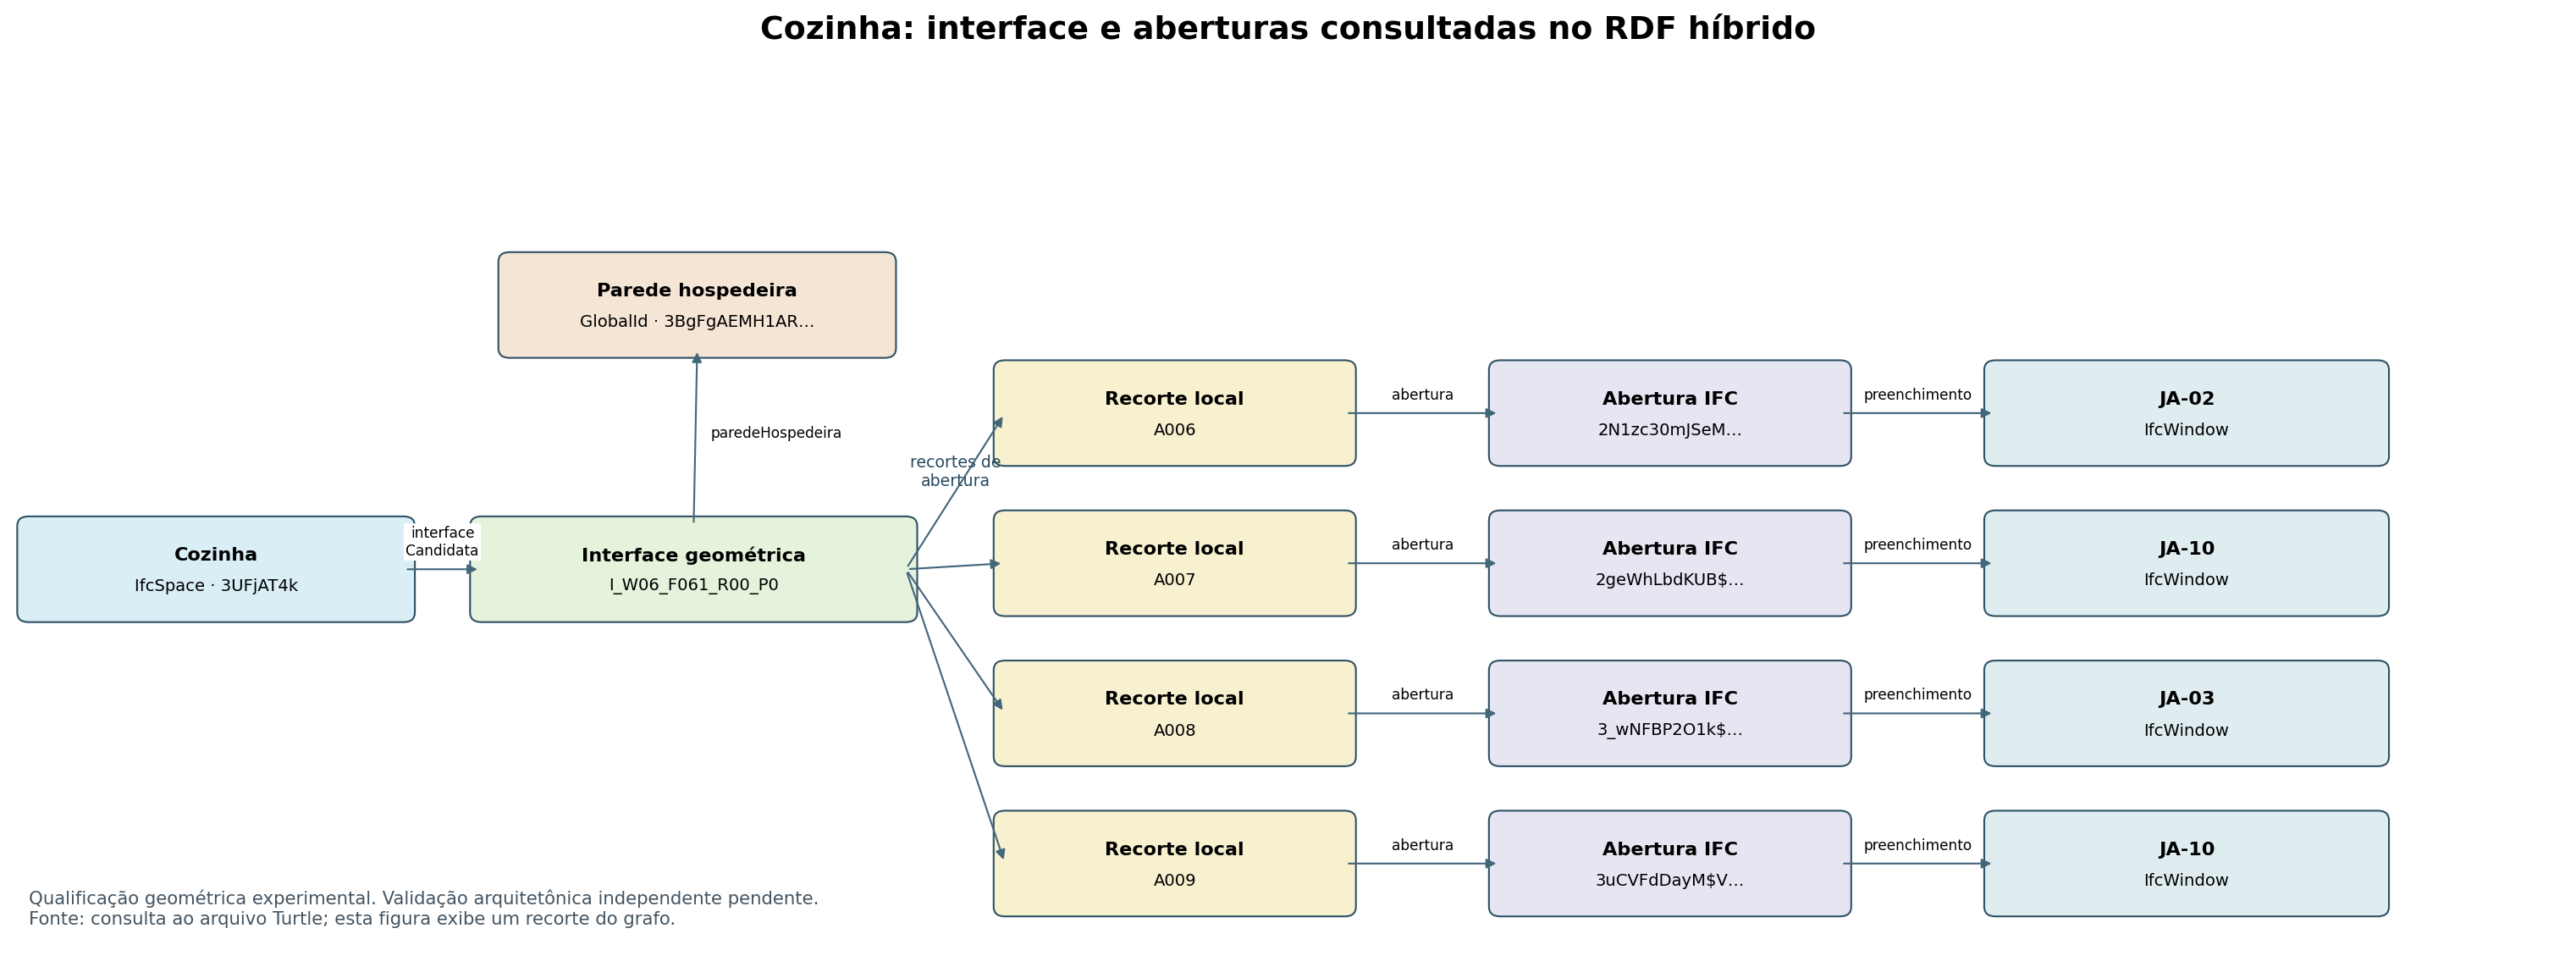

In [7]:
# Produz figura e relatório a partir do RDF efetivamente gerado.
from apresentar_resultados import run as apresentar
apresentar(SAIDA)
from IPython.display import display,Image
display(Image(filename=str(SAIDA/'Grafo_RDF_Recorte_Interface.png')))


## Integridade e conclusão do ensaio

O resultado coincide com o piloto anterior quanto às dez aberturas associadas. A contribuição é a combinação rastreável, com conferência de contornos e suporte geométrico adicional. Maior número de triplas não demonstra maior acurácia. A validação arquitetônica independente e a expansão aos demais ambientes continuam pendentes.

In [8]:
# Verifica preservação do IFC e de todas as triplas anteriores.
assert hashlib.sha256(IFC.read_bytes()).hexdigest()==IFC_SHA
anterior=rdflib.Graph().parse(RAIZ/'entrada/Grafo_Base_v05.ttl',format='turtle')
assert set(anterior).issubset(set(g))
assert len(g)==2559 and registro['avaliacoes_aberturas']==24
print('APROVADO: IFC preservado; 17 controles; 14 interfaces; 10 aberturas associadas; 24 avaliadas; 2559 triplas.')
print('Arquitetura completa e método de geração de Lilis 2026 não declarados como concluídos.')


APROVADO: IFC preservado; 17 controles; 14 interfaces; 10 aberturas associadas; 24 avaliadas; 2559 triplas.
Arquitetura completa e método de geração de Lilis 2026 não declarados como concluídos.
